# DSCI 552 — Homework 8

- **Name:** Yiming Lu
- **GitHub Username:** YeeDaco

All imports are in the first code cell (see `requirements.txt`). The data is loaded by the relative paths `../data/wdbc/` and `../data/banknote/`, so the notebook should be run from the `notebook/` folder. Every random step uses a seed derived from `SEED = 552`, so the notebook is reproducible.

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))

from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.special import softmax
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="Could not find the number of physical cores")
pd.set_option("display.width", 200)

SEED = 552
N_JOBS = -1
METRICS = ["accuracy", "precision", "recall", "F1", "AUC"]

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

### (a) Breast Cancer Wisconsin (Diagnostic) data

`wdbc.data` was downloaded from the UCI repository and is stored in `../data/wdbc/`. Each row has an ID, the diagnosis (B = benign, M = malignant) and 30 real-valued attributes: the mean, the standard error and the "worst" (mean of the three largest values) of 10 cell-nucleus measurements. The ID is not a feature. **Malignant is the positive class** ($y = 1$), benign the negative class ($y = 0$).

In [2]:
DATA1 = Path("../data/wdbc")
base = ["radius", "texture", "perimeter", "area", "smoothness", "compactness", "concavity",
        "concave_points", "symmetry", "fractal_dimension"]
feat1 = [f"{b}_{s}" for s in ["mean", "se", "worst"] for b in base]
wdbc = pd.read_csv(DATA1 / "wdbc.data", header=None, names=["id", "diagnosis"] + feat1)
X1 = wdbc[feat1].to_numpy()
y1 = (wdbc["diagnosis"] == "M").astype(int).to_numpy()
print("shape:", wdbc.shape, "| missing values:", wdbc.isna().sum().sum())
print("class counts:", wdbc["diagnosis"].value_counts().to_dict(), "| share of malignant: %.4f" % y1.mean())
wdbc[feat1].describe().T[["mean", "std", "min", "max"]].round(3).head(12)

shape: (569, 32) | missing values: 0
class counts: {'B': 357, 'M': 212} | share of malignant: 0.3726


,mean,std,min,max
radius_mean,14.127,3.524,6.981,28.110
texture_mean,19.290,4.301,9.710,39.280
perimeter_mean,91.969,24.299,43.790,188.500
area_mean,654.889,351.914,143.500,2501.000
smoothness_mean,0.096,0.014,0.053,0.163
compactness_mean,0.104,0.053,0.019,0.345
concavity_mean,0.089,0.080,0.000,0.427
concave_points_mean,0.049,0.039,0.000,0.201
symmetry_mean,0.181,0.027,0.106,0.304
fractal_dimension_mean,0.063,0.007,0.050,0.097


The attributes have very different scales (e.g. `area_mean` is in the hundreds, `smoothness_mean` around 0.1), so every method below works with **standardized** ("normalized") attributes. The scaler is always fitted on the training data of the run only.

### (b) Monte-Carlo simulation

In each of the $M = 30$ runs, a new random split puts 20% of the malignant **and** 20% of the benign rows into the test set (`train_test_split(..., stratify=y)`; 455 training and 114 test rows). The same split is used by all four methods in that run, so the methods are compared on exactly the same data. For every method the following scores are computed on the training and on the test set and averaged over the 30 runs: accuracy, precision, recall, $F_1$-score (all for the malignant class) and the AUC.

**Choice of the range for the penalty parameter (footnote 4).** `LinearSVC(penalty="l1", loss="squared_hinge", dual=False)` minimizes $\|w\|_1 + C \sum_i \max(0, 1 - y_i(w^\top x_i + b))^2$, so $C = 1/\lambda$ is the inverse of the penalty weight. Following the rule of thumb, an $\mathscr L_1$ SVM is trained on all the (standardized) data for $C = 10^{-4}, 10^{-3.5}, \dots, 10^{4}$, and the grid used for cross-validation is the range of $C$ (in half-decade steps of $\log C$) for which the training accuracy is not below 70%.

In [3]:
def l1_svm(C=1.0):
    return LinearSVC(penalty="l1", loss="squared_hinge", dual=False, C=C, tol=1e-4, max_iter=20000)


C_WIDE = 10.0 ** np.arange(-4, 4.01, 0.5)
Z1 = StandardScaler().fit_transform(X1)
chk = pd.DataFrame([{"log10 C": np.log10(C), "training accuracy": l1_svm(C).fit(Z1, y1).score(Z1, y1),
                     "non-zero weights": int((l1_svm(C).fit(Z1, y1).coef_ != 0).sum())} for C in C_WIDE])
display(chk.round(4).set_index("log10 C").T)
C_GRID1 = C_WIDE[chk["training accuracy"].to_numpy() >= 0.7]
print("C grid for 5-fold CV: 10^%s ... 10^%s (%d values)" % (np.log10(C_GRID1[0]), np.log10(C_GRID1[-1]), len(C_GRID1)))

log10 C,-4.0,-3.5,-3.0,-2.5,-2.0,-1.5,-1.0,-0.5,0.0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0
training accuracy,0.6274,0.6274,0.6274,0.9367,0.9701,0.9807,0.9877,0.9895,0.9895,0.9912,0.9895,0.9912,0.9947,0.9912,0.9912,0.9912,0.9912
non-zero weights,0.0000,0.0000,0.0000,4.0000,7.0000,9.0000,14.0000,17.0000,20.0000,26.0000,28.0000,29.0000,30.0000,28.0000,29.0000,29.0000,30.0000


C grid for 5-fold CV: 10^-2.5 ... 10^4.0 (14 values)


For very small $C$ (strong penalty) all weights are zero and the SVM predicts the majority class (accuracy $357/569 = 0.627 < 0.7$); from $C = 10^{-2.5}$ on, the training accuracy is above 70% (0.937). The CV grid is therefore $C \in \{10^{-2.5}, 10^{-2}, \dots, 10^{4}\}$ (14 values).

**Helper functions.** `scores` computes the five scores from the true labels, the predicted labels and a continuous score (for the AUC and ROC). The SVMs use the decision value $w^\top x + b$ as the score.

In [4]:
def scores(y, pred, score):
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "AUC": roc_auc_score(y, score)}


def split(seed):
    return train_test_split(X1, y1, test_size=0.2, stratify=y1, random_state=seed)


def cv5(seed):
    return StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)


def tune_l1(X, y, seed):
    # 5-fold CV for C on (already standardized) data X
    gs = GridSearchCV(l1_svm(), {"C": C_GRID1}, cv=cv5(seed), scoring="accuracy").fit(X, y)
    return gs.best_params_["C"], gs.best_score_


Xtr0, Xte0, ytr0, yte0 = split(SEED)
print("one split: train", Xtr0.shape, "class counts", np.bincount(ytr0), "| test", Xte0.shape, "class counts", np.bincount(yte0))

one split: train (455, 30) class counts [285 170] | test (114, 30) class counts [72 42]


#### i. Supervised learning: $\mathscr L_1$-penalized SVM

A pipeline *standardize → $\mathscr L_1$ linear SVM* is tuned by 5-fold stratified CV on the training set (the scaler is refitted inside each fold), refitted on the whole training set with the chosen $C$ and evaluated on the training and the test set.

In [5]:
def supervised(Xtr, ytr, Xte, yte, seed):
    pipe = Pipeline([("scale", StandardScaler()), ("svm", l1_svm())])
    gs = GridSearchCV(pipe, {"svm__C": C_GRID1}, cv=cv5(seed), scoring="accuracy").fit(Xtr, ytr)
    m = gs.best_estimator_
    out = {"C": gs.best_params_["svm__C"], "non-zero weights": int((m.named_steps["svm"].coef_ != 0).sum())}
    for part, X, y in [("train", Xtr, ytr), ("test", Xte, yte)]:
        out[part] = (y, m.predict(X), m.decision_function(X))
    return out

#### ii. Semi-supervised learning / self-training

- The scaler is fitted on all training attributes (labeled and unlabeled; this does not use any label).
- 50% of the malignant and 50% of the benign training rows are chosen at random as **labeled** data; the other half of the training set is **unlabeled** (its labels are hidden).
- **A.** An $\mathscr L_1$ SVM is trained on the labeled data, with $C$ chosen by 5-fold CV on the labeled data.
- **B.** The distance of an unlabeled point $x$ from the hyperplane $w^\top x + b = 0$ is $|w^\top x + b| / \|w\|_2$. The unlabeled point that is **farthest** from the boundary (the one the SVM is most confident about) gets the label predicted by the SVM, is moved to the labeled data, and the SVM is retrained (with the $C$ chosen in A). This is repeated until no unlabeled data are left (≈ 227 retrainings). The final SVM is evaluated on the whole training set (with its true labels) and on the test set.

The fraction of pseudo-labels that agree with the hidden true labels is also recorded.

In [6]:
def self_training(Xtr, ytr, Xte, yte, seed):
    scaler = StandardScaler().fit(Xtr)
    Ztr, Zte = scaler.transform(Xtr), scaler.transform(Xte)
    lab, unl = train_test_split(np.arange(len(ytr)), train_size=0.5, stratify=ytr, random_state=seed)
    C, _ = tune_l1(Ztr[lab], ytr[lab], seed)
    XL, yL = Ztr[lab], ytr[lab]
    U, U_true = Ztr[unl], ytr[unl]
    m = l1_svm(C).fit(XL, yL)
    out = {"C": C, "n labeled": len(lab), "n unlabeled": len(unl), "initial": {}}
    for part, Z, y in [("train", Ztr, ytr), ("test", Zte, yte)]:   # SVM trained on the labeled half only
        out["initial"][part] = scores(y, m.predict(Z), m.decision_function(Z))
    pseudo_ok = 0
    while len(U):
        dist = np.abs(m.decision_function(U)) / max(np.linalg.norm(m.coef_), 1e-12)
        j = int(np.argmax(dist))
        y_hat = int(m.predict(U[j:j + 1])[0])
        pseudo_ok += y_hat == U_true[j]
        XL, yL = np.vstack([XL, U[j]]), np.append(yL, y_hat)
        U, U_true = np.delete(U, j, axis=0), np.delete(U_true, j)
        m = l1_svm(C).fit(XL, yL)
    out["pseudo-label accuracy"] = pseudo_ok / len(unl)
    out["non-zero weights"] = int((m.coef_ != 0).sum())
    for part, Z, y in [("train", Ztr, ytr), ("test", Zte, yte)]:
        out[part] = (y, m.predict(Z), m.decision_function(Z))
    return out

#### iii. Unsupervised learning: k-means with $k = 2$

**A. Avoiding a bad local minimum.** Lloyd's algorithm only converges to a local minimum of the within-cluster sum of squares $W = \sum_{c} \sum_{i \in c} \|x_i - \mu_c\|^2$, and the result depends on the initial centers. Therefore k-means is run **50 times with random initial centers** (`init="random"`: two training points chosen at random as initial centers, each with a different random seed), and the solution with the **smallest** $W$ is kept. If many independent random starts end at the same smallest $W$, it is very unlikely that all of them were trapped in the same non-global local minimum, so the best solution is (with high probability) the global minimum. This is checked for the first run below by looking at the distribution of the 50 final $W$ values.

k-means is run on the whole (standardized) training set without the labels.

**B. Labeling the clusters.** For each of the two centers, the 30 training points closest to it are found; the majority of their true labels becomes the label of the whole cluster (the 30 points are "labeled by experts"). Every training point gets the label of its cluster.

**C. Test data** are assigned to the nearest center and get the label of that cluster.

**Score for ROC / AUC (footnote 2).** k-means does not give probabilities. The distances $d_1, d_2$ of a point to the two centers are passed through a softmax, $p_c = e^{-d_c} / (e^{-d_1} + e^{-d_2})$, and the score of "malignant" is the sum of $p_c$ over the clusters labeled malignant. If one cluster is labeled M and the other B, this is the soft membership of the malignant cluster.

In [7]:
N_INIT = 50


def best_kmeans(Z, seed):
    fits = [KMeans(n_clusters=2, init="random", n_init=1, random_state=seed * 1000 + r).fit(Z) for r in range(N_INIT)]
    inertia = np.array([f.inertia_ for f in fits])
    return fits[int(np.argmin(inertia))], inertia


def kmeans_classifier(Xtr, ytr, Xte, yte, seed):
    scaler = StandardScaler().fit(Xtr)
    Ztr, Zte = scaler.transform(Xtr), scaler.transform(Xte)
    km, inertia = best_kmeans(Ztr, seed)
    D = km.transform(Ztr)                                    # distances of training points to both centers
    closest = np.argsort(D, axis=0)[:30]                     # 30 closest training points to each center
    votes_M = ytr[closest].sum(axis=0)                       # malignant votes among the 30 points of each center
    cl_label = (votes_M >= 15).astype(int)                   # majority poll (a 15:15 tie is labeled malignant)
    out = {"inertia": inertia, "best inertia": inertia.min(), "cluster labels": cl_label,
           "cluster sizes": np.bincount(km.labels_, minlength=2), "votes M": votes_M}
    for part, Z, y in [("train", Ztr, ytr), ("test", Zte, yte)]:
        d = km.transform(Z)
        p = softmax(-d, axis=1)
        out[part] = (y, cl_label[km.predict(Z)], (p * (cl_label == 1)).sum(axis=1))
    return out

#### iv. Spectral clustering

**What is spectral clustering?** It treats the data as a graph: the points are the nodes and the edges are weighted by a similarity (kernel) $A_{ij} = \exp(-\gamma \|x_i - x_j\|^2)$ (RBF kernel). With the degree matrix $D = \mathrm{diag}(\sum_j A_{ij})$, it computes the eigenvectors of the (normalized) graph Laplacian $L = I - D^{-1/2} A D^{-1/2}$ belonging to the $k$ smallest eigenvalues, uses them as a new $k$-dimensional representation of the points (the *spectral embedding*), and finally runs k-means in that embedding. This is a relaxation of the normalized-cut problem: it looks for clusters with strong connections inside and weak connections between them. Because the clusters are defined by connectivity, not by distance to a center, they can be non-convex, and spectral clustering does not have cluster centers. Therefore the labels are obtained with `fit_predict`.

**Setup.**

- Spectral clustering has no `predict` for new points. To classify the test data with `fit_predict` (and not by proximity to a center), the clustering is run once on the standardized training **and** test attributes together, without any labels. Only the **training** labels are used to name the clusters, so the test labels are never used.
- **Choice of $\gamma$.** With $\gamma = 1$ on the 30 standardized attributes the squared distances are of order 60, so almost all kernel values are $\approx 0$ and the graph falls apart: the clustering just cuts off a couple of outliers (shown below). Following the assignment, $\gamma$ is instead chosen in every run from $\{10^{-3.5}, 10^{-3.33}, \dots, 10^{-1.5}\}$ so that the two clusters have the same balance as the two classes in the original data set ($212 : 357$, i.e. the smaller cluster should contain 37.26% of the points): the $\gamma$ whose smaller cluster share is closest to 0.3726 is used. This only uses the class proportions, not the labels of individual points.
- **Labeling (footnote 3).** Every cluster gets the majority label of **all** its training members.
- **ROC (footnote 3).** A cluster is labeled malignant if the share $t_c$ of malignant training points in it is at least a threshold $t$ (the usual majority vote is $t = 50\%$). Varying $t$ from 0 to 1 gives the ROC curve, so the score of a point is $t_c$ of its cluster. With two clusters the ROC curve has only one point between $(0,0)$ and $(1,1)$.

In [8]:
GAMMAS = 10.0 ** np.linspace(-3.5, -1.5, 13)
TARGET = y1.mean()                                            # 212 / 569


def spectral_labels(Z, gamma, seed):
    return SpectralClustering(n_clusters=2, affinity="rbf", gamma=gamma, assign_labels="kmeans",
                              random_state=seed).fit_predict(Z)


def spectral_classifier(Xtr, ytr, Xte, yte, seed):
    scaler = StandardScaler().fit(Xtr)
    Z = np.vstack([scaler.transform(Xtr), scaler.transform(Xte)])
    n_tr = len(ytr)
    best = None
    for g in GAMMAS:
        lab = spectral_labels(Z, g, seed)
        share = np.bincount(lab, minlength=2).min() / len(lab)
        if best is None or abs(share - TARGET) < best[0]:
            best = (abs(share - TARGET), g, lab, share)
    _, gamma, lab, share = best
    frac_M = np.array([ytr[lab[:n_tr] == c].mean() if np.any(lab[:n_tr] == c) else 0.0 for c in range(2)])
    cl_label = (frac_M >= 0.5).astype(int)
    out = {"gamma": gamma, "smaller cluster share": share, "cluster labels": cl_label, "share M in cluster": frac_M}
    for part, idx, y in [("train", slice(0, n_tr), ytr), ("test", slice(n_tr, None), yte)]:
        out[part] = (y, cl_label[lab[idx]], frac_M[lab[idx]])
    return out


# gamma = 1 on the first split
Zchk = StandardScaler().fit(Xtr0).transform(np.vstack([Xtr0, Xte0]))
lab1 = spectral_labels(Zchk, 1.0, SEED)
print("gamma = 1: cluster sizes", np.bincount(lab1))
for g in GAMMAS:
    print("gamma = %.5f: cluster sizes %s" % (g, np.bincount(spectral_labels(Zchk, g, SEED))))

gamma = 1: cluster sizes [567   2]
gamma = 0.00032: cluster sizes [377 192]
gamma = 0.00046: cluster sizes [377 192]
gamma = 0.00068: cluster sizes [377 192]
gamma = 0.00100: cluster sizes [377 192]
gamma = 0.00147: cluster sizes [378 191]
gamma = 0.00215: cluster sizes [379 190]
gamma = 0.00316: cluster sizes [386 183]
gamma = 0.00464: cluster sizes [393 176]
gamma = 0.00681: cluster sizes [401 168]
gamma = 0.01000: cluster sizes [412 157]
gamma = 0.01468: cluster sizes [421 148]
gamma = 0.02154: cluster sizes [567   2]
gamma = 0.03162: cluster sizes [567   2]


#### Running the Monte-Carlo simulation

Every run uses the seed `SEED + run` for its split, its CV folds, the labeled/unlabeled split, the k-means initializations and spectral clustering. The 30 runs are independent and are run in parallel.

In [9]:
METHODS = {"supervised L1 SVM": supervised, "self-training L1 SVM": self_training,
           "k-means": kmeans_classifier, "spectral clustering": spectral_classifier}
M_RUNS = 30


def one_run(run):
    seed = SEED + run
    with threadpool_limits(1):
        Xtr, Xte, ytr, yte = split(seed)
        res = {}
        for name, f in METHODS.items():
            out = f(Xtr, ytr, Xte, yte, seed)
            out["scores"] = {part: scores(*out[part]) for part in ["train", "test"]}
            res[name] = out
    return res


t0 = time.time()
runs = Parallel(n_jobs=N_JOBS)(delayed(one_run)(r) for r in range(M_RUNS))
print("%d runs in %.1f s" % (M_RUNS, time.time() - t0))

rows = [{"run": r, "method": name, "set": part, **runs[r][name]["scores"][part]}
        for r in range(M_RUNS) for name in METHODS for part in ["train", "test"]]
mc1 = pd.DataFrame(rows)

30 runs in 129.6 s


#### Results of one run (run 0): ROC curves and confusion matrices

The ROC curves and confusion matrices of all four methods for the first Monte-Carlo run (seed 552), on the training and on the test set.

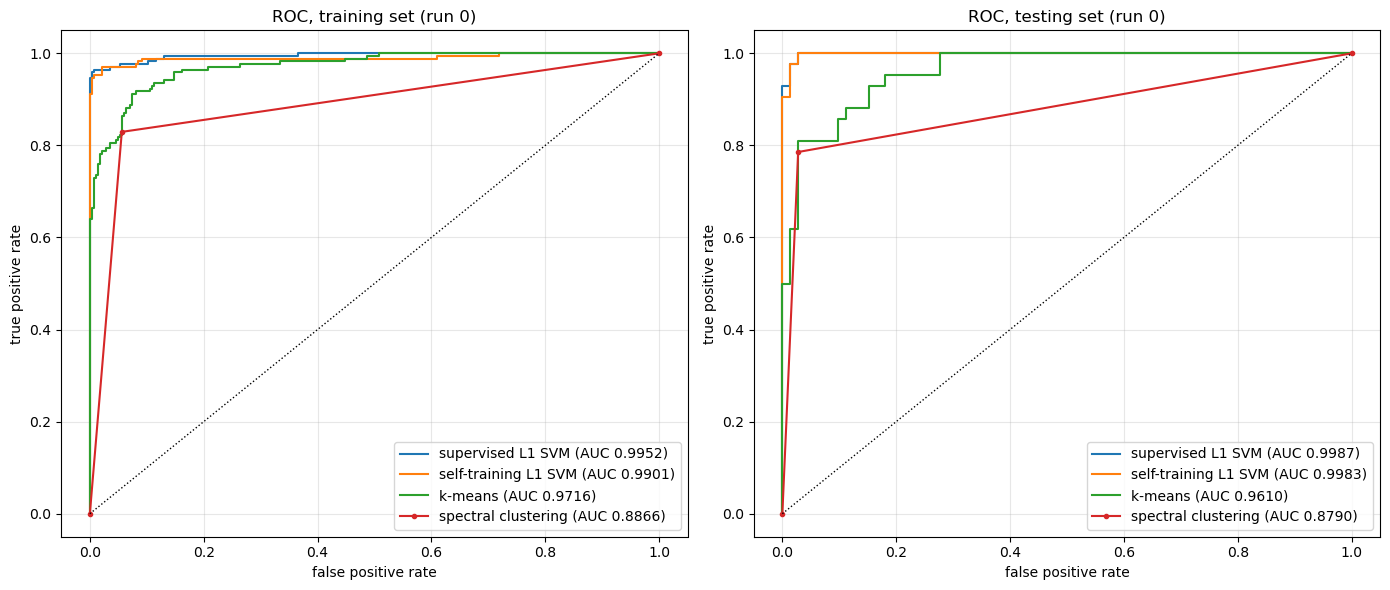

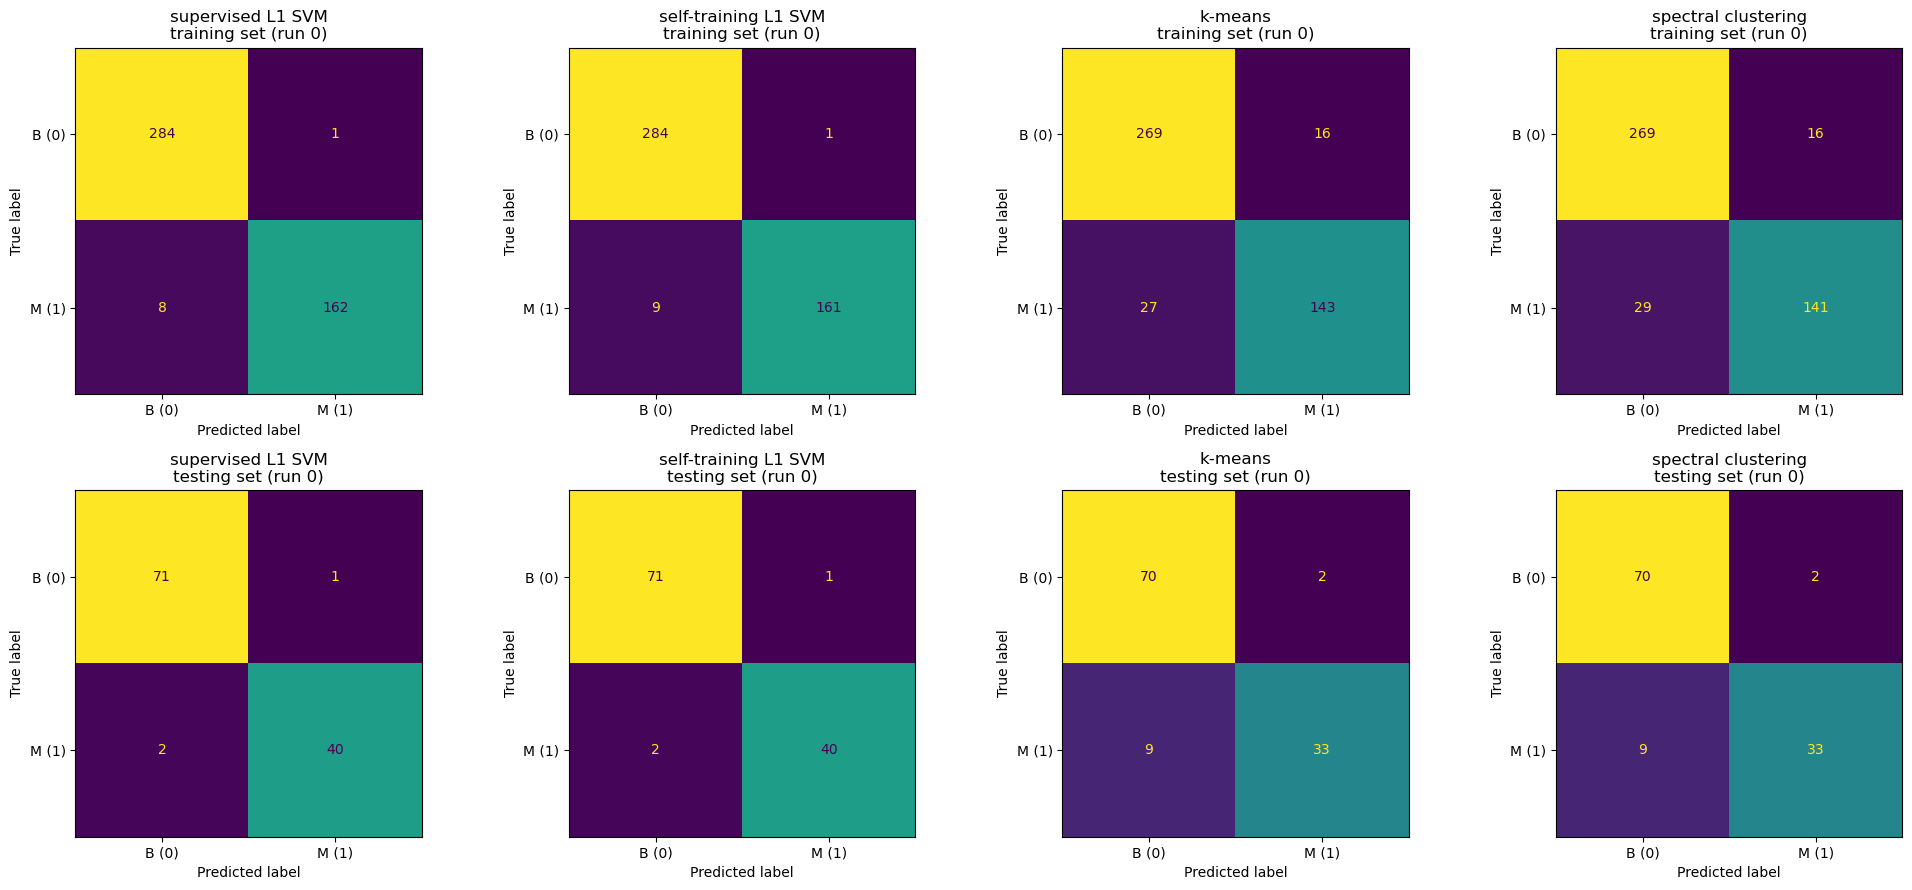

supervised L1 SVM      train  TN=284 FP=  1 FN=  8 TP=162
supervised L1 SVM      test   TN= 71 FP=  1 FN=  2 TP= 40
self-training L1 SVM   train  TN=284 FP=  1 FN=  9 TP=161
self-training L1 SVM   test   TN= 71 FP=  1 FN=  2 TP= 40
k-means                train  TN=269 FP= 16 FN= 27 TP=143
k-means                test   TN= 70 FP=  2 FN=  9 TP= 33
spectral clustering    train  TN=269 FP= 16 FN= 29 TP=141
spectral clustering    test   TN= 70 FP=  2 FN=  9 TP= 33


In [10]:
R0 = runs[0]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, part in zip(axes, ["train", "test"]):
    for name in METHODS:
        y, pred, s = R0[name][part]
        fpr, tpr, _ = roc_curve(y, s)
        ax.plot(fpr, tpr, marker="." if name == "spectral clustering" else None,
                label="%s (AUC %.4f)" % (name, roc_auc_score(y, s)))
    ax.plot([0, 1], [0, 1], "k:", lw=1)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.set_title(f"ROC, {part}ing set (run 0)")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for j, name in enumerate(METHODS):
    for i, part in enumerate(["train", "test"]):
        y, pred, _ = R0[name][part]
        ConfusionMatrixDisplay.from_predictions(y, pred, labels=[0, 1], display_labels=["B (0)", "M (1)"],
                                                ax=axes[i, j], colorbar=False)
        axes[i, j].set_title(f"{name}\n{part}ing set (run 0)")
plt.tight_layout()
plt.show()

for name in METHODS:
    for part in ["train", "test"]:
        y, pred, _ = R0[name][part]
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        print("%-22s %-5s  TN=%3d FP=%3d FN=%3d TP=%3d" % (name, part, tn, fp, fn, tp))

Details of run 0: the chosen penalty parameters, the self-training procedure, the k-means restarts and the chosen $\gamma$.

supervised: C = 0.0316228, non-zero weights = 10 of 30
self-training: 227 labeled, 228 unlabeled, C = 0.316228, pseudo-label accuracy = 0.9649, non-zero weights = 12 of 30
  SVM on the labeled half only (step A): test {'accuracy': 0.9825, 'precision': 0.9762, 'recall': 0.9762, 'F1': 0.9762, 'AUC': 0.9987}
  after self-training (step B):           test {'accuracy': 0.9737, 'precision': 0.9756, 'recall': 0.9524, 'F1': 0.9639, 'AUC': 0.9983}
k-means: cluster sizes [296 159], malignant votes among the 30 closest points [ 0 30] -> cluster labels [0 1]
spectral: gamma = 0.00032, smaller cluster share = 0.3374, share of M in the clusters [0.097 0.898] -> labels [0 1]


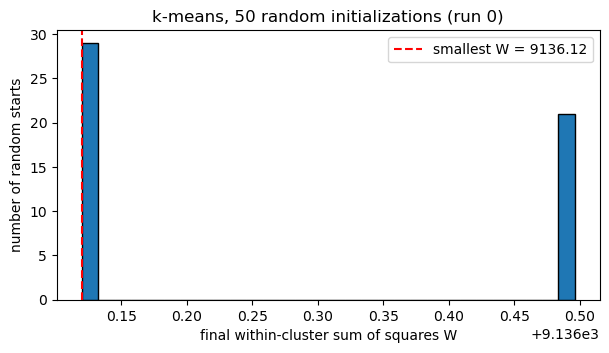

share of the 50 random starts that reach the smallest W: 0.58
over all 30 runs: share of starts reaching the best W, min = 0.02, mean = 0.39


In [11]:
print("supervised: C = %g, non-zero weights = %d of 30" % (R0["supervised L1 SVM"]["C"], R0["supervised L1 SVM"]["non-zero weights"]))
st = R0["self-training L1 SVM"]
print("self-training: %d labeled, %d unlabeled, C = %g, pseudo-label accuracy = %.4f, non-zero weights = %d of 30"
      % (st["n labeled"], st["n unlabeled"], st["C"], st["pseudo-label accuracy"], st["non-zero weights"]))
print("  SVM on the labeled half only (step A): test", {k: round(v, 4) for k, v in st["initial"]["test"].items()})
print("  after self-training (step B):           test", {k: round(v, 4) for k, v in st["scores"]["test"].items()})
km0 = R0["k-means"]
print("k-means: cluster sizes %s, malignant votes among the 30 closest points %s -> cluster labels %s"
      % (km0["cluster sizes"], km0["votes M"], km0["cluster labels"]))
sp0 = R0["spectral clustering"]
print("spectral: gamma = %.5f, smaller cluster share = %.4f, share of M in the clusters %s -> labels %s"
      % (sp0["gamma"], sp0["smaller cluster share"], sp0["share M in cluster"].round(3), sp0["cluster labels"]))

inertia = km0["inertia"]
plt.figure(figsize=(7, 3.5))
plt.hist(inertia, bins=30, edgecolor="k")
plt.axvline(inertia.min(), color="r", ls="--", label="smallest W = %.2f" % inertia.min())
plt.xlabel("final within-cluster sum of squares W")
plt.ylabel("number of random starts")
plt.title("k-means, 50 random initializations (run 0)")
plt.legend()
plt.show()
share_best = np.mean(np.isclose(inertia, inertia.min(), rtol=1e-6))
print("share of the 50 random starts that reach the smallest W: %.2f" % share_best)
print("over all 30 runs: share of starts reaching the best W, min = %.2f, mean = %.2f"
      % tuple((lambda a: (a.min(), a.mean()))(np.array([np.mean(np.isclose(r["k-means"]["inertia"], r["k-means"]["inertia"].min(), rtol=1e-6)) for r in runs]))))

#### Average scores over the $M = 30$ runs

In [12]:
avg = mc1.groupby(["set", "method"], sort=False)[METRICS].mean()
std = mc1.groupby(["set", "method"], sort=False)[METRICS].std()
order = list(METHODS)
for part in ["train", "test"]:
    print(f"average {part}ing scores over {M_RUNS} runs (mean ± standard deviation)")
    tab = avg.loc[part].loc[order].round(4).astype(str) + " ± " + std.loc[part].loc[order].round(4).astype(str)
    display(tab)

average training scores over 30 runs (mean ± standard deviation)


,accuracy,precision,recall,F1,AUC
method,,,,,
supervised L1 SVM,0.985 ± 0.0034,0.9918 ± 0.0051,0.9678 ± 0.0099,0.9796 ± 0.0046,0.9972 ± 0.0011
self-training L1 SVM,0.9754 ± 0.0069,0.9819 ± 0.0129,0.952 ± 0.0197,0.9665 ± 0.0097,0.9935 ± 0.0033
k-means,0.9124 ± 0.0083,0.926 ± 0.0198,0.8324 ± 0.0111,0.8766 ± 0.011,0.9751 ± 0.0036
spectral clustering,0.9097 ± 0.0069,0.9227 ± 0.015,0.828 ± 0.0134,0.8727 ± 0.0097,0.8933 ± 0.0075


average testing scores over 30 runs (mean ± standard deviation)


,accuracy,precision,recall,F1,AUC
method,,,,,
supervised L1 SVM,0.9711 ± 0.0151,0.975 ± 0.0189,0.946 ± 0.0359,0.9599 ± 0.0216,0.9932 ± 0.0075
self-training L1 SVM,0.9637 ± 0.0172,0.9717 ± 0.029,0.9294 ± 0.034,0.9496 ± 0.0239,0.9909 ± 0.0095
k-means,0.907 ± 0.0241,0.9262 ± 0.0379,0.8135 ± 0.0504,0.8653 ± 0.0357,0.9727 ± 0.0123
spectral clustering,0.9044 ± 0.0265,0.9224 ± 0.0459,0.8103 ± 0.051,0.8616 ± 0.0383,0.8848 ± 0.0301


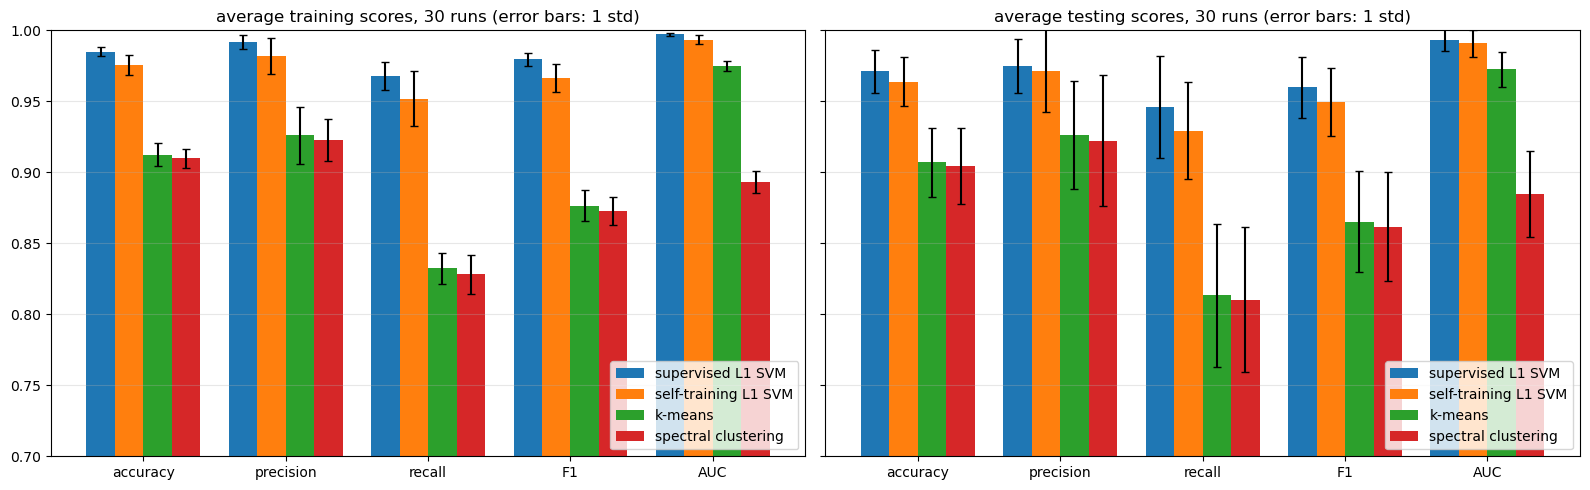

self-training: mean pseudo-label accuracy = 0.9632; mean test accuracy of the step-A SVM (labeled half only) = 0.9646
spectral clustering: chosen gamma in the 30 runs: {0.00032: 29, 0.00068: 1}
k-means: runs in which both clusters got the same label: 0


,chosen C (median),non-zero weights (mean)
supervised L1 SVM,0.100000,12.7
self-training L1 SVM,0.316228,14.8
k-means,NaN,NaN
spectral clustering,NaN,NaN


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, part in zip(axes, ["train", "test"]):
    avg.loc[part].loc[order].T.plot.bar(ax=ax, yerr=std.loc[part].loc[order].T, capsize=3, width=0.8, rot=0)
    ax.set_ylim(0.7, 1.0)
    ax.set_title(f"average {part}ing scores, {M_RUNS} runs (error bars: 1 std)")
    ax.legend(loc="lower right")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

extra = pd.DataFrame({
    "chosen C (median)": [np.median([r["supervised L1 SVM"]["C"] for r in runs]), np.median([r["self-training L1 SVM"]["C"] for r in runs]), np.nan, np.nan],
    "non-zero weights (mean)": [np.mean([r["supervised L1 SVM"]["non-zero weights"] for r in runs]),
                                np.mean([r["self-training L1 SVM"]["non-zero weights"] for r in runs]), np.nan, np.nan],
}, index=order)
print("self-training: mean pseudo-label accuracy = %.4f; mean test accuracy of the step-A SVM (labeled half only) = %.4f"
      % (np.mean([r["self-training L1 SVM"]["pseudo-label accuracy"] for r in runs]),
         np.mean([r["self-training L1 SVM"]["initial"]["test"]["accuracy"] for r in runs])))
print("spectral clustering: chosen gamma in the 30 runs:", pd.Series([round(r["spectral clustering"]["gamma"], 5) for r in runs]).value_counts().sort_index().to_dict())
print("k-means: runs in which both clusters got the same label:", sum(r["k-means"]["cluster labels"][0] == r["k-means"]["cluster labels"][1] for r in runs))
extra

#### v. Comparison

Average **test** scores over the 30 runs (training scores in parentheses):

| method | accuracy | precision | recall | $F_1$ | AUC |
|---|---|---|---|---|---|
| supervised $\mathscr L_1$ SVM | **0.971** (0.985) | **0.975** (0.992) | **0.946** (0.968) | **0.960** (0.980) | **0.993** (0.997) |
| self-training $\mathscr L_1$ SVM | 0.964 (0.975) | 0.972 (0.982) | 0.929 (0.952) | 0.950 (0.967) | 0.991 (0.994) |
| k-means ($k = 2$) | 0.907 (0.912) | 0.926 (0.926) | 0.814 (0.832) | 0.865 (0.877) | 0.973 (0.975) |
| spectral clustering | 0.904 (0.910) | 0.922 (0.923) | 0.810 (0.828) | 0.862 (0.873) | 0.885 (0.893) |

- **The expected order holds: supervised > semi-supervised > unsupervised.** The supervised $\mathscr L_1$ SVM is best in every score. Its CV chooses a fairly strong penalty (median $C = 0.1$, on average only 12.7 of the 30 weights are non-zero), and the small gap between training and test scores shows that it does not overfit.
- **Semi-supervised learning is only slightly worse** (test accuracy 0.964 vs. 0.971, $F_1$ 0.950 vs. 0.960, AUC 0.991 vs. 0.993), although only half of the training labels are used. The diagnosis is almost linearly separable, so about 227 labeled points are already enough for a good linear boundary. **Self-training itself adds practically nothing:** the SVM of step A, trained on the labeled half only, already has an average test accuracy of 0.9646, and after self-training it is 0.9637. The points that are added first are the ones *farthest* from the boundary, i.e. the ones the SVM is already sure about, so they hardly move the boundary. In addition, about 3.7% of the pseudo-labels are wrong (pseudo-label accuracy 0.963). These wrong labels are added near the end, close to the boundary, where they matter most. The main effect is a slightly lower recall (0.929 vs. 0.946).
- **Unsupervised learning is clearly worse** (test accuracy ≈ 0.905, about 6–7 percentage points below the SVMs). Both clustering methods find almost the same two groups, and labeling them works perfectly (in run 0 the 30 points closest to the centers are 30/30 malignant and 0/30 malignant; both clusters got the same label in no run). The problem is the clusters themselves: the clusters separate large, irregular nuclei from small, regular ones, which is related to, but not the same as, the diagnosis. About 19% of the malignant tumours look "benign-like" and fall into the benign cluster (recall ≈ 0.81), while precision stays high (≈ 0.92). Because no labels are used to fit the clusters, the training and test scores are almost equal.
- **k-means vs. spectral clustering.** With the $\gamma$ chosen for balance, the spectral clusters are practically the k-means clusters, and accuracy, precision, recall and $F_1$ are within 0.004 of each other. $\gamma = 1$ is useless for 30 standardized attributes (clusters of 567 and 2 points), and so is every $\gamma \ge 0.02$. For small $\gamma$ the smaller cluster has at most 34% of the points, so the balance $212:357$ (37.3%) is never reached exactly, and the closest one is at the smallest $\gamma$ of the grid ($10^{-3.5}$ in 29 of 30 runs). For such a small $\gamma$ the RBF kernel is very smooth, and the cut is almost the same as the k-means split. The lower AUC of spectral clustering (0.885 vs. 0.973) is caused by its score, not by worse clusters: the majority-poll threshold gives only two different score values, so its ROC curve has a single corner point. The softmax of the k-means distances is a continuous score that ranks the points inside each cluster as well.
- **Local minima in k-means (iii A).** In 30 runs, on average 39% of the 50 random initializations reach the smallest $W$ (58% in run 0), and the other starts end in a few worse local minima. Keeping the best of 50 random starts is therefore necessary. In one run only 1 of the 50 starts reached the best $W$, so a single random start, or even only a few, would often stop in a worse local minimum. With 50 starts the chance that every start misses a minimum that is reached by 39% of the starts is negligible.
- **Summary.** Labels are valuable: with all labels the linear SVM makes about 3 errors per 114 test cases. With half the labels it makes about 4, and self-training does not help to get back the difference. Without labels (except the 30 "expert" labels per cluster) k-means and spectral clustering make about 11 errors, and most of them are missed malignant tumours. That is the worst kind of error in this application.

## 2. Active Learning Using Support Vector Machines

### (a) Banknote authentication data

The data (1,372 banknote images, 4 wavelet features: variance, skewness, curtosis, entropy; class 0 = genuine, 1 = forged) is stored in `../data/banknote/`. 472 rows are chosen at random as the test set and the remaining 900 as the training set. This split is fixed for the whole problem; the Monte-Carlo randomness comes from the random pools. The features are standardized with a scaler fitted on the 900 training rows.

In [14]:
DATA2 = Path("../data/banknote")
bank = pd.read_csv(DATA2 / "data_banknote_authentication.txt", header=None,
                   names=["variance", "skewness", "curtosis", "entropy", "class"])
X2, y2 = bank.iloc[:, :4].to_numpy(), bank["class"].to_numpy()
print("shape:", bank.shape, "| class counts:", bank["class"].value_counts().sort_index().to_dict())

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X2, y2, test_size=472, random_state=SEED)
sc2 = StandardScaler().fit(Xb_tr)
Zb_tr, Zb_te = sc2.transform(Xb_tr), sc2.transform(Xb_te)
print("training set:", Zb_tr.shape, np.bincount(yb_tr), "| test set:", Zb_te.shape, np.bincount(yb_te))

shape: (1372, 5) | class counts: {0: 762, 1: 610}
training set: (900, 4) [512 388] | test set: (472, 4) [250 222]


### (b) Passive and active learning

**Range of the penalty parameter (footnote 4).** As in problem 1, an $\mathscr L_1$ linear SVM is trained on all 900 training points for $C = 10^{-5}, \dots, 10^{5}$, and the CV grid is the set of $C$ (one value per decade of $\log C$, to keep the 9,000 cross-validations affordable) for which the training accuracy is at least 70%.

In [15]:
C_WIDE2 = 10.0 ** np.arange(-5, 6)
chk2 = pd.DataFrame([{"log10 C": int(np.log10(C)), "training accuracy": l1_svm(C).fit(Zb_tr, yb_tr).score(Zb_tr, yb_tr)} for C in C_WIDE2])
display(chk2.round(4).set_index("log10 C").T)
C_GRID2 = C_WIDE2[chk2["training accuracy"].to_numpy() >= 0.7]
print("C grid: 10^%d ... 10^%d" % (np.log10(C_GRID2[0]), np.log10(C_GRID2[-1])))

log10 C,-5,-4,-3,-2,-1,0,1,2,3,4,5
training accuracy,0.5689,0.5689,0.8567,0.9689,0.9844,0.9889,0.9933,0.9922,0.9922,0.9922,0.9922


C grid: 10^-3 ... 10^5


**Procedure (one Monte-Carlo run).**

- **Initial pool.** 10 training points are drawn at random. If all of them belong to one class, another set of 10 is drawn (footnote 5). To make 5-fold *stratified* CV possible, the pool is also redrawn if one class has only one point. The same initial pool is used by the passive and the active learner of a run, so the two are compared from the same starting point.
- **Training an SVM on a pool.** A linear SVM with $\mathscr L_1$ penalty; $C$ is chosen from the grid by stratified 5-fold CV on the pool (for very small pools in which the minority class has fewer than 5 points, the number of folds is the size of the minority class, at least 2). Ties are broken in favour of the smaller $C$, as in `GridSearchCV`. The SVM is refitted on the whole pool and its error on the 472 test points is recorded.
- **i. Passive learning.** 10 more points are drawn at random (without replacement) from the remaining training points and added to the pool.
- **ii. Active learning.** The distance of each remaining training point from the hyperplane is $|w^\top x + b| / \|w\|_2$; the 10 points **closest** to the hyperplane (the points the SVM is least sure about) are added to the pool. (If all weights are 0, the distances are all equal and 10 random points are taken.) Their labels are then used, i.e. they are "queried".
- This is repeated until all 900 training points are in the pool: 90 SVMs trained with 10, 20, …, 900 points and 90 test errors per run.

Each procedure is repeated 50 times (seeds `SEED + run`).

In [16]:
def fit_cv(X, y, seed):
    k = min(5, np.bincount(y, minlength=2).min())
    folds = list(StratifiedKFold(n_splits=k, shuffle=True, random_state=seed).split(X, y))
    acc = [np.mean([l1_svm(C).fit(X[tr], y[tr]).score(X[va], y[va]) for tr, va in folds]) for C in C_GRID2]
    C = C_GRID2[int(np.argmax(acc))]
    return l1_svm(C).fit(X, y), C


def initial_pool(rng):
    while True:
        pool = rng.choice(len(yb_tr), 10, replace=False)
        if np.bincount(yb_tr[pool], minlength=2).min() >= 2:
            return pool


def learning_curve(run, active):
    seed = SEED + run
    rng = np.random.default_rng(seed)
    pool = list(initial_pool(rng))
    rest = np.setdiff1d(np.arange(len(yb_tr)), pool)
    rng = np.random.default_rng([seed, int(active)])
    errors, Cs = [], []
    with threadpool_limits(1):
        while True:
            m, C = fit_cv(Zb_tr[pool], yb_tr[pool], seed)
            errors.append(1 - m.score(Zb_te, yb_te))
            Cs.append(C)
            if len(rest) == 0:
                break
            if active and np.linalg.norm(m.coef_) > 0:
                dist = np.abs(m.decision_function(Zb_tr[rest])) / np.linalg.norm(m.coef_)
                pick = np.argsort(dist, kind="stable")[:10]
            else:
                pick = rng.choice(len(rest), 10, replace=False)
            pool += list(rest[pick])
            rest = np.delete(rest, pick)
    return errors, Cs


N_RUNS2 = 50
t0 = time.time()
curves = Parallel(n_jobs=N_JOBS)(delayed(learning_curve)(r, a) for a in [False, True] for r in range(N_RUNS2))
print("%d learning curves in %.1f s" % (len(curves), time.time() - t0))
sizes = np.arange(10, 901, 10)
err = {"passive": np.array([c[0] for c in curves[:N_RUNS2]]), "active": np.array([c[0] for c in curves[N_RUNS2:]])}
Cs2 = {"passive": np.array([c[1] for c in curves[:N_RUNS2]]), "active": np.array([c[1] for c in curves[N_RUNS2:]])}
print({k: v.shape for k, v in err.items()}, "(runs x SVMs)")

100 learning curves in 1653.4 s
{'passive': (50, 90), 'active': (50, 90)} (runs x SVMs)


### (c) Learning curves by Monte-Carlo simulation

For each of the 90 pool sizes, the 50 test errors are averaged.

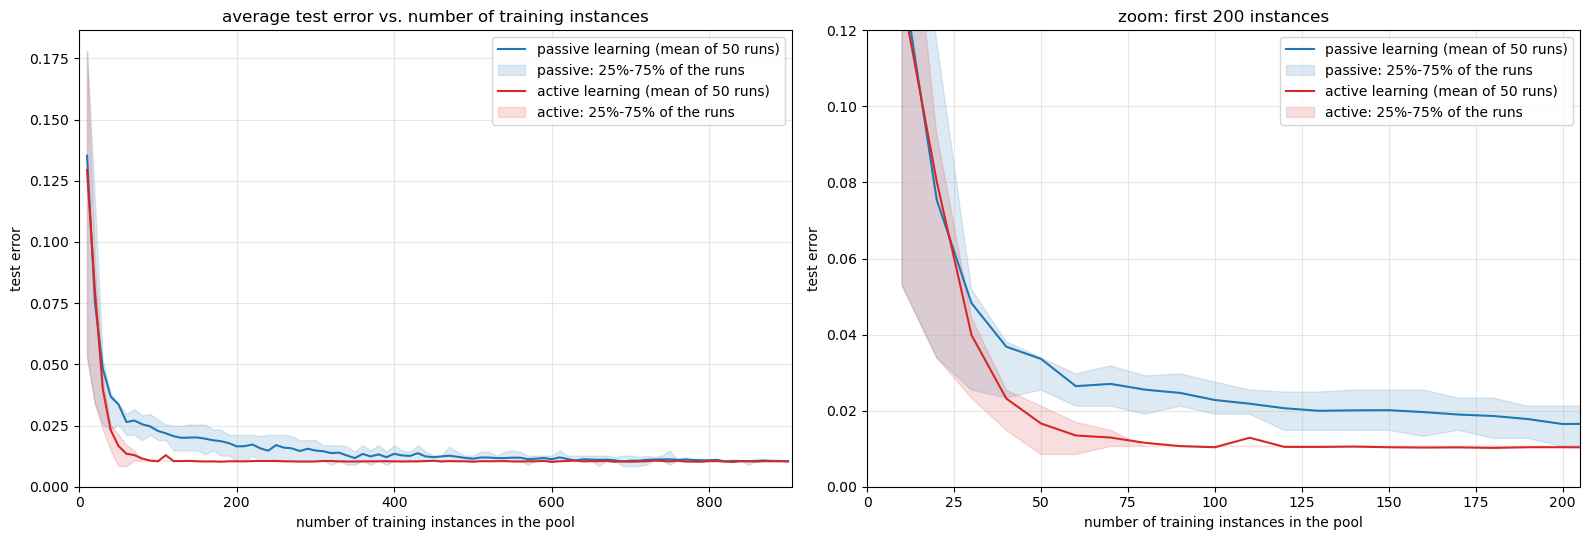

pool size,10,20,30,40,50,60,80,100,150,200,300,400,500,600,700,800,900
passive,0.1353,0.0754,0.0483,0.0368,0.0336,0.0264,0.0255,0.0228,0.0201,0.0165,0.0148,0.0134,0.0114,0.0112,0.0106,0.0108,0.0104
active,0.1294,0.0802,0.0399,0.0232,0.0166,0.0135,0.0115,0.0104,0.0104,0.0104,0.0103,0.0103,0.0102,0.0101,0.0102,0.0104,0.0103
active - passive,-0.0059,0.0048,-0.0084,-0.0136,-0.0170,-0.0130,-0.0140,-0.0124,-0.0097,-0.0061,-0.0045,-0.0031,-0.0012,-0.0011,-0.0004,-0.0004,-0.0001


passive: smallest pool whose average test error is within 0.002 of the full-pool error (0.0104): 350
active : smallest pool whose average test error is within 0.002 of the full-pool error (0.0104): 80
pool sizes where active is better: 87 of 90; minimum average test error: passive 0.0103, active 0.0101


In [17]:
mean_err = {k: v.mean(axis=0) for k, v in err.items()}
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, xmax in zip(axes, [900, 200]):
    for k, col in [("passive", "tab:blue"), ("active", "tab:red")]:
        q25, q75 = np.percentile(err[k], [25, 75], axis=0)
        ax.plot(sizes, mean_err[k], color=col, label=f"{k} learning (mean of 50 runs)")
        ax.fill_between(sizes, q25, q75, color=col, alpha=0.15, label=f"{k}: 25%-75% of the runs")
    ax.set_xlim(0, xmax + 5)
    ax.set_xlabel("number of training instances in the pool")
    ax.set_ylabel("test error")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_title("average test error vs. number of training instances")
axes[1].set_title("zoom: first 200 instances")
axes[1].set_ylim(0, 0.12)
plt.tight_layout()
plt.show()

curve = pd.DataFrame({"passive": mean_err["passive"], "active": mean_err["active"]}, index=pd.Index(sizes, name="pool size"))
curve["active - passive"] = curve["active"] - curve["passive"]
display(curve.loc[[10, 20, 30, 40, 50, 60, 80, 100, 150, 200, 300, 400, 500, 600, 700, 800, 900]].round(4).T)
full = curve.loc[900, "passive"]
for k in ["passive", "active"]:
    print("%-7s: smallest pool whose average test error is within 0.002 of the full-pool error (%.4f): %d"
          % (k, full, sizes[np.argmax(mean_err[k] <= full + 0.002)]))
print("pool sizes where active is better: %d of 90; minimum average test error: passive %.4f, active %.4f"
      % ((curve["active - passive"] < 0).sum(), mean_err["passive"].min(), mean_err["active"].min()))

**Conclusions.**

- **Both learners start and end at the same place.** With 10 points the average test error is about 13% for both; with all 900 points both pools are the whole training set and the error is 1.04%.
- **Active learning reaches the final accuracy far sooner.** At 50 labeled points the average test error is 1.7% for active and 3.4% for passive learning; at 100 points it is 1.04% vs. 2.28%. The active learner's average test error is within 0.002 of the full-pool error already with **80** points, and the passive learner needs **350** points for the same. After about 100 points the active learning curve is flat, while the passive one keeps decreasing slowly until about 600 points. Active learning is better at 87 of the 90 pool sizes.
- **Why.** The SVM hyperplane depends only on the points near the margin (the support vectors). Active learning asks for the labels of the points closest to the current hyperplane, which are exactly the points that can still change it. Random sampling mostly adds points far from the boundary, which the SVM already classifies correctly and which carry little information. Once the active learner has found the boundary region, the remaining points are far away and do not change the SVM. This is why its curve stays flat at the final error.
- **The very beginning is the exception.** At 20 points active learning is slightly worse (8.0% vs. 7.5%). With 10 points the first hyperplane can be poor, and its 10 closest points are a biased sample (all from a narrow strip around a wrong boundary). After two or three rounds the active learner overtakes the passive one.
- **Conclusion.** The learning curves obtained by Monte-Carlo simulation show that, for the same accuracy, active learning needs only about a quarter of the labels that passive learning needs (≈ 80–100 vs. ≈ 350). This matters when labeling is expensive. For a linear SVM on this almost linearly separable problem, labeling more than ~100 well-chosen points gives practically no benefit.